# 5.4. Використання збереженої CNN

Цей ноутбук завантажує фінальну CNN-модель і ZIP із зображеннями з відкритого репозиторію. Перевіряємо 10 тестових цифр MNIST і 10 зовнішніх зображень. У наборі 7 реальних історичних сканів DIDA та 3 зображення, згенеровані ШІ. Походження та ліцензія збережені всередині ZIP-файлу.

In [1]:
from pathlib import Path  # Імпортуємо зручний інструмент для роботи зі шляхами файлів.
import json, csv, urllib.request, zipfile  # Підключаємо читання метаданих, таблиць, завантажень і ZIP-архівів.
import numpy as np  # Підключаємо масиви й числові обчислення.
import matplotlib.pyplot as plt  # Підключаємо побудову графіків і зображень.
from PIL import Image  # Підключаємо відкриття графічних файлів.
import cv2  # Підключаємо обробку зображень для виділення рукописних цифр.
import tensorflow as tf  # Підключаємо TensorFlow для роботи з нейромережею.
from tensorflow import keras  # Підключаємо Keras API для завантаження та оцінювання моделі.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()  # Визначаємо папку Lab5 незалежно від того, звідки відкрито ноутбук.
(ROOT/'results').mkdir(exist_ok=True)  # Створюємо папку для таблиць і графіків цього запуску.
GITHUB_RAW = 'https://raw.githubusercontent.com/MTGMODS/dl_labs/main/Lab5/'  # Задаємо адресу файлів у відкритому репозиторії.
def ensure_file(relative_path):  # Оголошуємо функцію, яка за потреби завантажує відсутній файл.
    destination = ROOT/relative_path  # Формуємо шлях, куди покладемо потрібний файл.
    if not destination.exists():  # Перевіряємо, чи файл уже є в поточній папці.
        destination.parent.mkdir(parents=True, exist_ok=True)  # Створюємо батьківські папки, якщо їх ще немає.
        urllib.request.urlretrieve(GITHUB_RAW+relative_path, destination)  # Завантажуємо файл із відкритого GitHub-репозиторію.
    return destination  # Повертаємо шлях, щоб наступний код міг відкрити файл.
model_path = ensure_file('models/best_mnist_cnn.keras')  # Завантажуємо єдину фінальну CNN-модель.
cnn_loaded = keras.models.load_model(model_path, compile=False)  # Відкриваємо збережені ваги та архітектуру мережі.
cnn_loaded.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])  # Налаштовуємо метрики для evaluate без повторного навчання.
cnn_loaded.summary()  # Показуємо шари й кількість параметрів моделі.

Model: "cnn_deeper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 96)       │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 96)       │        83,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 864)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       110,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,010 (1.21 MB)

 Trainable params: 315,626 (1.20 MB)

 Non-trainable params: 384 (1.50 KB)

## 1. Десять тестових цифр MNIST
Беремо по одному прикладу кожного класу з тестового набору. Вибір індексів і seed зафіксовано до прогнозування.

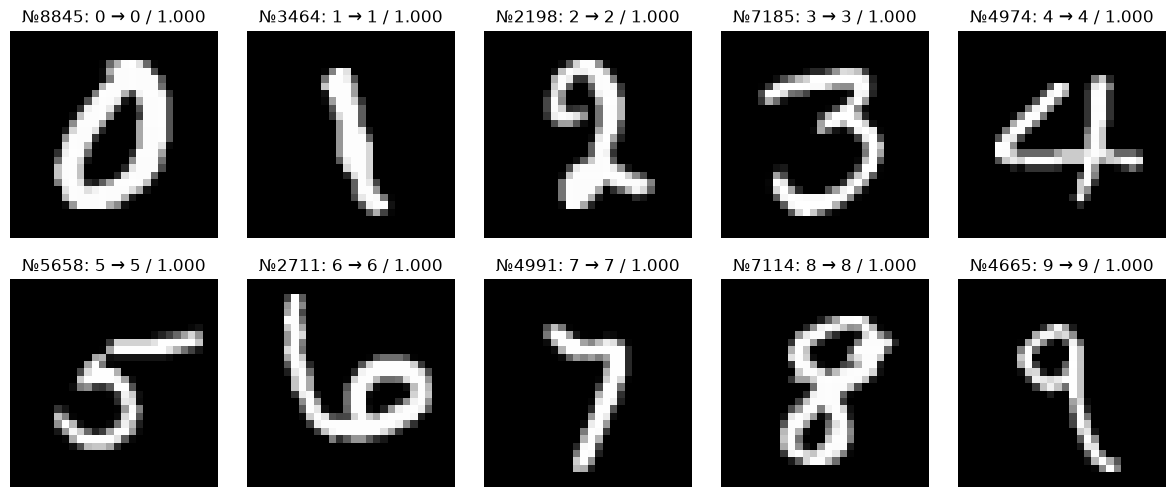

MNIST 10: 10 /10


In [2]:
_, (mnist_images, mnist_labels) = keras.datasets.mnist.load_data()  # Завантажуємо офіційний тестовий набір MNIST і правильні мітки.
rng = np.random.default_rng(2026)  # Фіксуємо генератор для відтворюваного вибору прикладів.
sample_indices = np.array([rng.choice(np.flatnonzero((mnist_labels == digit) & (np.arange(len(mnist_labels)) >= 2000))) for digit in range(10)])  # Вибираємо один тестовий приклад кожної цифри.
mnist_batch = mnist_images[sample_indices].astype('float32')[..., None]/255.0  # Додаємо канал зображення та нормалізуємо пікселі до [0, 1].
mnist_probabilities = cnn_loaded.predict(mnist_batch, verbose=0)  # Отримуємо ймовірності CNN для десяти вибраних цифр.
mnist_predictions = np.argmax(mnist_probabilities, axis=1)  # Перетворюємо ймовірності на передбачені номери цифр.
fig, axes = plt.subplots(2,5,figsize=(12,5))  # Створюємо сітку для показу десяти результатів.
for ax, idx, prediction, probs in zip(axes.flat, sample_indices, mnist_predictions, mnist_probabilities):  # Проходимо по зображеннях та їх прогнозах.
    ax.imshow(mnist_images[idx], cmap='gray'); ax.axis('off')  # Показуємо цифру у відтінках сірого та вимикаємо осі.
    ax.set_title(f'№{idx}: {mnist_labels[idx]} → {prediction} / {max(probs):.3f}')  # Порівнюємо правильну мітку, відповідь і впевненість.
fig.tight_layout(h_pad=2.5); fig.savefig(ROOT/'results/cnn_10_mnist.png', dpi=160); plt.show()  # Зберігаємо та показуємо рисунок.
mnist_10_correct = int(np.sum(mnist_predictions == mnist_labels[sample_indices]))  # Рахуємо правильні відповіді для десяти MNIST-прикладів.
print('MNIST 10:', mnist_10_correct, '/10')  # Виводимо кількість правильних відповідей.

## 2. Зовнішні зображення та їх походження
Завантажуємо один ZIP-архів. Усередині є 7 реальних сканів DIDA, 3 приклади, згенеровані ШІ, маніфест походження та ліцензія. Це зображення іншого походження, а не персональні фото автора; вони не використовувалися для навчання.

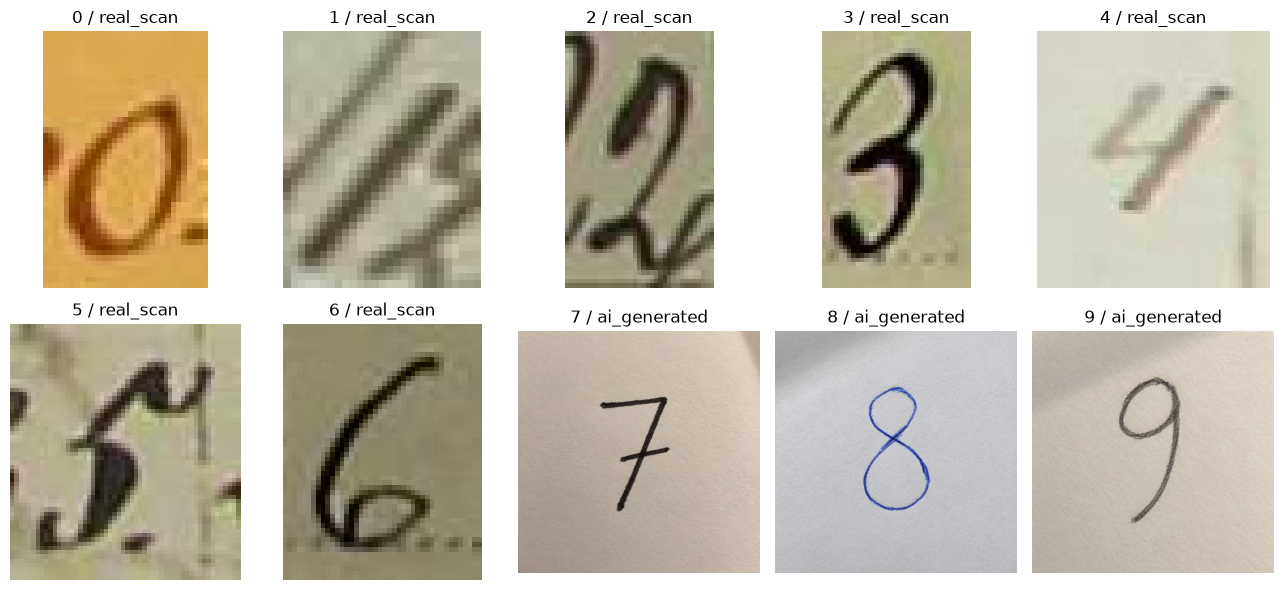

In [3]:
archive_path = ensure_file('digit_images.zip')  # Завантажуємо ZIP із десятьма власними для експерименту зображеннями.
with zipfile.ZipFile(archive_path) as archive:  # Відкриваємо архів у режимі читання.
    archive.extractall(ROOT)  # Розпаковуємо зразки, маніфест і ліцензію у папку Lab5.
manifest = json.loads((ROOT/'images/manifest.json').read_text(encoding='utf8'))  # Читаємо цифру та походження кожного файла.
assert len(manifest) == 10  # Перевіряємо, що в наборі рівно десять зразків.
assert sum(item['origin']=='real_scan' for item in manifest)==7  # Перевіряємо кількість реальних сканів.
assert sum(item['origin']=='ai_generated' for item in manifest)==3  # Перевіряємо кількість зображень ШІ.
external_paths = [ROOT/'images'/item['filename'] for item in manifest]  # Формуємо шляхи до всіх десяти зображень.
external_labels = np.array([item['label'] for item in manifest])  # Збираємо правильні мітки у числовий масив.
fig, axes = plt.subplots(2,5,figsize=(13,6))  # Готуємо сітку для перегляду всіх початкових зразків.
for ax, path, item in zip(axes.flat, external_paths, manifest):  # Перебираємо зображення разом із підписами походження.
    ax.imshow(Image.open(path)); ax.set_title(f"{item['label']} / {item['origin']}"); ax.axis('off')  # Показуємо зразок, мітку та походження.
fig.tight_layout(); fig.savefig(ROOT/'results/external_originals.png', dpi=160); plt.show()  # Зберігаємо та показуємо початкові файли.

## 3. Однакова обробка зображень
Переводимо зображення у сірий колір, підсилюємо контраст за фіксованими квантилями, порогом Otsu відділяємо штрихи, а маскою знаходимо найбільшу зв’язну компоненту. Цифру вписуємо у 20×20, центруємо на полі 28×28 і нормалізуємо. Однакова процедура застосована до всіх десяти файлів.

CNN input: (10, 28, 28, 1) 0.0 0.9764706


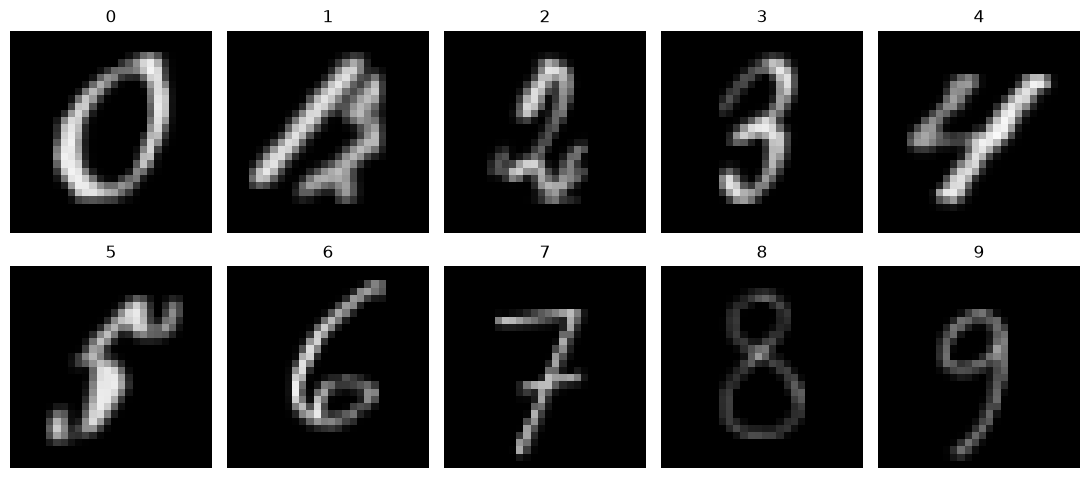

In [4]:
def preprocess_digit(image_path):  # Оголошуємо функцію підготовки одного зображення до формату MNIST.
    gray = np.array(Image.open(image_path).convert('L'))  # Відкриваємо файл і переводимо його у градації сірого.
    dark = 255-gray  # Інвертуємо світлий папір, щоб штрихи стали світлими на темному тлі.
    lo, hi = np.percentile(dark, [5, 99])  # Вимірюємо межі контрасту без впливу крайніх значень.
    contrast = np.clip((dark.astype('float32')-lo)/max(hi-lo, 1)*255, 0, 255).astype('uint8')  # Розтягуємо контраст і обмежуємо його діапазоном 0–255.
    _, mask = cv2.threshold(contrast, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)  # Автоматично відокремлюємо штрихи від фону.
    kernel_size = max(3, int(min(mask.shape)*.003) | 1)  # Обчислюємо невелике непарне ядро для з’єднання розривів.
    joined_mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((kernel_size,kernel_size),np.uint8))  # Замикаємо дрібні проміжки лише у масці пошуку.
    count, components, stats, centroids = cv2.connectedComponentsWithStats(joined_mask, 8)  # Знаходимо окремі з’єднані ділянки штрихів.
    if count < 2:  # Перевіряємо, чи після фону залишився хоч один компонент.
        raise ValueError(f'Не знайдено цифру: {image_path}')  # Зупиняємося з назвою файла, якщо цифру не знайдено.
    largest = 1+np.argmax(stats[1:, cv2.CC_STAT_AREA])  # Вибираємо найбільший компонент, не враховуючи тло.
    x,y,w,h,area = stats[largest]  # Читаємо рамку та площу вибраної цифри.
    ink = np.where(components==largest, contrast, 0).astype('uint8')[y:y+h,x:x+w]  # Вирізаємо цифру з початковим рівнем сірого.
    scale = 20/max(w,h)  # Обчислюємо масштаб, щоб зберегти пропорції та вмістити цифру у 20 пікселів.
    resized = cv2.resize(ink, (max(1,round(w*scale)),max(1,round(h*scale))), interpolation=cv2.INTER_AREA)  # Зменшуємо або збільшуємо вирізаний фрагмент.
    centered = np.zeros((28,28), dtype='uint8')  # Створюємо чорне полотно потрібного MNIST-розміру.
    dx, dy = (28-resized.shape[1])//2, (28-resized.shape[0])//2  # Обчислюємо поля для розміщення цифри посередині.
    centered[dy:dy+resized.shape[0], dx:dx+resized.shape[1]] = resized  # Кладемо цифру на чорне полотно.
    moments = cv2.moments(centered)  # Обчислюємо центр мас штрихів.
    if moments['m00']:  # Перевіряємо, що зображення має ненульову площу штрихів.
        shift = np.float32([[1,0,13.5-moments['m10']/moments['m00']], [0,1,13.5-moments['m01']/moments['m00']]])  # Рахуємо зсув центру мас до середини кадру.
        centered = cv2.warpAffine(centered, shift, (28,28))  # Зсуваємо цифру, не змінюючи розмір кадру.
    return centered.astype('float32')/255.0  # Повертаємо пікселі у форматі float від нуля до одиниці.
external_processed = np.stack([preprocess_digit(p) for p in external_paths])  # Обробляємо усі десять зразків і складаємо їх у пакет.
external_batch = external_processed[...,None]  # Додаємо канал кольору, якого очікує згорткова мережа.
print('CNN input:', external_batch.shape, external_batch.min(), external_batch.max())  # Перевіряємо форму пакета та діапазон пікселів.
fig, axes = plt.subplots(2,5,figsize=(11,5))  # Готуємо сітку для перегляду оброблених цифр.
for ax, image, item in zip(axes.flat, external_processed, manifest):  # Перебираємо цифри та їх правильні мітки.
    ax.imshow(image, cmap='gray', vmin=0, vmax=1); ax.set_title(str(item['label'])); ax.axis('off')  # Показуємо вхід нейромережі та правильну мітку.
fig.tight_layout(); fig.savefig(ROOT/'results/external_processed.png', dpi=160); plt.show()  # Зберігаємо та показуємо підготовлені зразки.

## 4. Прогнозування та оцінка
Модель повертає ймовірності десяти цифр; argmax вибирає клас із найбільшим значенням. Максимальна ймовірність не гарантує правильність. Зберігаємо прогноз для кожного файла, включно з помилками.

{
  "total_correct": 6,
  "total": 10,
  "real_correct": 4,
  "real_total": 7,
  "ai_correct": 2,
  "ai_total": 3
}
{'filename': 'real_0_DIDA_873.jpg', 'origin': 'real_scan', 'expected': 0, 'cnn_prediction': 0, 'cnn_confidence': 1.0, 'cnn_correct': True}
{'filename': 'real_1_DIDA_946.jpg', 'origin': 'real_scan', 'expected': 1, 'cnn_prediction': 0, 'cnn_confidence': 0.7553274631500244, 'cnn_correct': False}
{'filename': 'real_2_DIDA_821.jpg', 'origin': 'real_scan', 'expected': 2, 'cnn_prediction': 1, 'cnn_confidence': 0.6679127812385559, 'cnn_correct': False}
{'filename': 'real_3_DIDA_977.jpg', 'origin': 'real_scan', 'expected': 3, 'cnn_prediction': 3, 'cnn_confidence': 0.9999914169311523, 'cnn_correct': True}
{'filename': 'real_4_DIDA_884.jpg', 'origin': 'real_scan', 'expected': 4, 'cnn_prediction': 1, 'cnn_confidence': 0.9051440358161926, 'cnn_correct': False}
{'filename': 'real_5_DIDA_932.jpg', 'origin': 'real_scan', 'expected': 5, 'cnn_prediction': 5, 'cnn_confidence': 0.99863380193

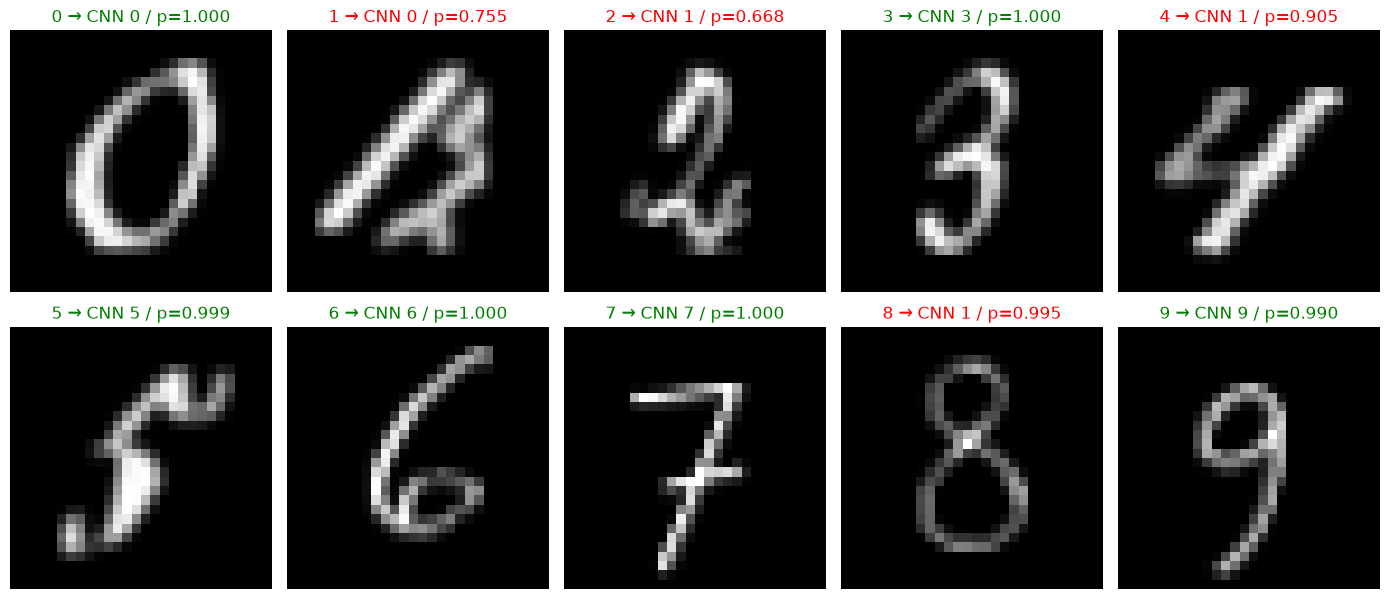

In [5]:
external_cnn_probs = cnn_loaded.predict(external_batch, verbose=0)  # Обчислюємо ймовірності класів CNN для десяти зовнішніх цифр.
external_cnn_predictions = external_cnn_probs.argmax(axis=1)  # Вибираємо цифру з найбільшою прогнозованою ймовірністю.
prediction_rows = []  # Створюємо порожній список для результатів кожного зразка.
for i,item in enumerate(manifest):  # Проходимо по маніфесту, щоб зіставити прогноз із правильною міткою.
    prediction_rows.append(dict(filename=item['filename'], origin=item['origin'], expected=int(item['label']),  # Записуємо назву файла, походження та правильну цифру.
        cnn_prediction=int(external_cnn_predictions[i]), cnn_confidence=float(external_cnn_probs[i].max()),  # Зберігаємо відповідь CNN та найбільшу ймовірність.
        cnn_correct=bool(external_cnn_predictions[i]==item['label'])))  # Фіксуємо, чи збіглася відповідь із правильною міткою.
with (ROOT/'results/external_predictions.csv').open('w',encoding='utf8',newline='') as f:  # Відкриваємо CSV-файл для збереження таблиці.
    writer=csv.DictWriter(f,fieldnames=list(prediction_rows[0]));writer.writeheader();writer.writerows(prediction_rows)  # Записуємо назви стовпців та всі прогнози.
(ROOT/'results/external_predictions.json').write_text(json.dumps(prediction_rows,ensure_ascii=False,indent=2),encoding='utf8')  # Зберігаємо повні результати у JSON.
cnn_real = [r for r in prediction_rows if r['origin']=='real_scan']  # Відбираємо результати для семи реальних сканів.
cnn_ai = [r for r in prediction_rows if r['origin']=='ai_generated']  # Відбираємо результати для трьох зображень ШІ.
summary = dict(total_correct=sum(r['cnn_correct'] for r in prediction_rows), total=len(prediction_rows),  # Рахуємо загальну точність на десяти зовнішніх зображеннях.
    real_correct=sum(r['cnn_correct'] for r in cnn_real), real_total=len(cnn_real), ai_correct=sum(r['cnn_correct'] for r in cnn_ai), ai_total=len(cnn_ai))  # Окремо рахуємо скани та зображення ШІ.
(ROOT/'results/external_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf8')  # Записуємо підсумкові лічильники.
print(json.dumps(summary,indent=2))  # Виводимо точність для перевірки.
for row in prediction_rows: print(row)  # Показуємо повний рядок кожного результату, зокрема помилки.
fig, axes = plt.subplots(2,5,figsize=(14,6))  # Створюємо сітку для десяти фінальних прогнозів.
for ax, image, row in zip(axes.flat, external_processed, prediction_rows):  # Перебираємо зображення разом з їхніми прогнозами.
    ax.imshow(image,cmap='gray'); ax.axis('off')  # Показуємо оброблену цифру без координатних осей.
    ax.set_title(f"{row['expected']} → CNN {row['cnn_prediction']} / p={row['cnn_confidence']:.3f}",color='green' if row['cnn_correct'] else 'red')  # Зеленим позначаємо правильну, червоним помилкову відповідь.
fig.tight_layout(h_pad=2.5);fig.savefig(ROOT/'results/external_predictions.png',dpi=160);plt.show()  # Зберігаємо та показуємо всі відповіді CNN.

## 5. Перевірка якості на MNIST
Оцінюємо збережену модель на повному офіційному тестовому наборі. Це окрема перевірка від десяти прикладів MNIST і десяти зовнішніх зображень.

In [6]:
test_targets = keras.utils.to_categorical(mnist_labels,10)  # Перетворюємо тестові мітки на one-hot формат для цієї CNN.
full_test = mnist_images.astype('float32')[...,None]/255.0  # Додаємо канал і нормалізуємо всі тестові зображення.
test_loss, test_accuracy = cnn_loaded.evaluate(full_test,test_targets,batch_size=200,verbose=0)  # Обчислюємо втрату й точність на всіх тестових цифрах.
quality = dict(test_accuracy=float(test_accuracy),test_loss=float(test_loss),test_images=len(mnist_labels))  # Формуємо підсумок оцінювання.
(ROOT/'results/final_model_test.json').write_text(json.dumps(quality,indent=2),encoding='utf8')  # Зберігаємо оцінки, щоб їх можна було відтворити.
print(quality)  # Виводимо тестову якість фінальної моделі.

{'test_accuracy': 0.9909999966621399, 'test_loss': 0.03340642526745796, 'test_images': 10000}


## Висновок
На тестовій вибірці MNIST фінальна CNN має точність близько 99%. На десяти зовнішніх зображеннях вона розпізнала 6/10 цифр: 4/7 реальних сканів і 2/3 зображення ШІ. Невеликий набір не дає підстав робити загальний висновок про всі рукописні чи ШІ-зображення. Помилки збережені у таблиці; зовнішні зразки не використовувалися для навчання або налаштування моделі.